In [34]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
from tqdm import trange

# from dualwcfm.trainers.dual_trainer import DualTrainer, DualTrainerConfig
# from dualwcfm.visualization import plot_2d_flow_trajectories
# from dualwcfm.models.cfm import ConditionalFlowMatching
# from dualwcfm.trainers.dynamic_trainer import DynamicTrainer
# from dualwcfm.models.cfm import torch_wrapper
# from dualwcfm.trainers.wcfm import CFMTrainerConfig
from torchcfm.models.models import MLP
from dualwcfm.distributions.distribution import Distribution
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution
from dualwcfm.distributions import CouplingDistribution, RotatedShapeCoupling, Simple2DGaussianDistribution, RotatedDistribution, MoonDistribution

In [36]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [37]:
import torch
import torch.nn as nn
from torchdyn.core import NeuralODE

class LagrangianFlowField(nn.Module):
    """
    Wraps a velocity network to handle 'Source Conditioning'.
    State z = [x_t, x_0] (Dimension 2*D)
    Dynamics: dx/dt = net(x_t, x_0, t), dx_0/dt = 0
    """
    def __init__(self, net, dim):
        super().__init__()
        self.net = net
        self.dim = dim

    def forward(self, x):
        x_t = x[:, :self.dim]      # Current Position (Evolving)
        x_0 = x[:, self.dim:2*self.dim]      # Initial Position (Constant Context)

        # if isinstance(t, torch.Tensor) and t.dim() == 0:
        #      t = t.repeat(z.shape[0], 1)
        # elif isinstance(t, float):
        #      t = torch.full((z.shape[0], 1), t).to(z.device)

        # net_input = torch.cat([x_t, x_0, t], dim=1)

        v_x = self.net(x)
        v_c = torch.zeros_like(x_0)
        return torch.cat([v_x, v_c], dim=1)

<Figure size 800x800 with 0 Axes>

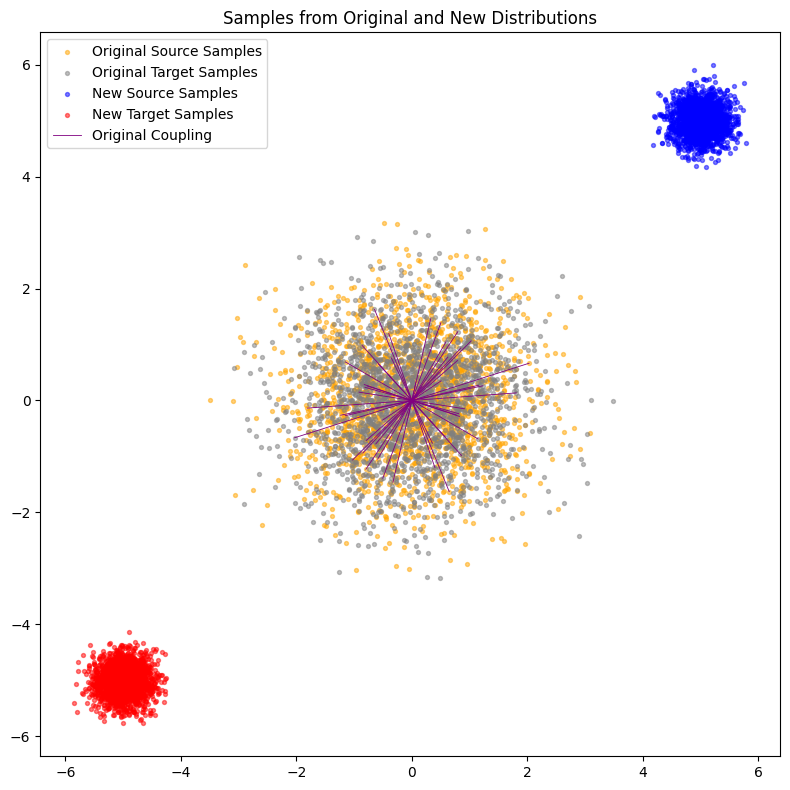

In [38]:
def anticorrelate(n: int):
    source_samples = torch.randn(n, 2)
    return source_samples, -source_samples

coupling_dist = FunctionalCouplingDistribution(anticorrelate)
source_dist, target_dist = coupling_dist.get_marginals()
new_source_dist = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([0.25, 0.25]))
new_target_dist = Simple2DGaussianDistribution(mean=torch.tensor([-5.0, -5.0]), std=torch.tensor([0.25, 0.25]))

# coupling_dist = RotatedShapeCoupling(
#     centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
#     source_scale=0.2,
#     target_scale=0.2,
#     rotation_degrees=90.0,
#     source_shift=(0.0, 0.0),
#     target_shift=(0.0, 0.0),
#     device=device
# )
# new_coupling_dist = RotatedShapeCoupling(
#     centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
#     source_scale=0.2,
#     target_scale=0.2,
#     rotation_degrees=90.0,
#     source_shift=(2.5, 2.5),
#     target_shift=(2.5, -2.5),
# )
# source_dist, target_dist = coupling_dist.get_marginals()
# new_source_dist, new_target_dist = new_coupling_dist.get_marginals()

plt.figure(figsize=(8, 8))
n_samples = 2000
coupling_samples = coupling_dist.coupling_sample(n_samples)
source_samples = coupling_samples[0].cpu().numpy()
target_samples = coupling_samples[1].cpu().numpy()
new_source_samples = new_source_dist.sample(n_samples).cpu().numpy()
new_target_samples = new_target_dist.sample(n_samples).cpu().numpy()

fig = plt.figure(figsize=(8, 8))
plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=1.0, lw=0.6, label='Original Coupling')
plt.title('Samples from Original and New Distributions')
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.tight_layout()
plt.show()

## Learn marginal Conditional Flow Matching

In [39]:
from dualwcfm.visualizer import plot_2d_flow_trajectories
from dualwcfm.cfm import ConditionalFlowMatching

Training Marginal Bridges: 100%|██████████| 2500/2500 [00:14<00:00, 167.43it/s, Loss mu=0.435, Loss nu=0.422]


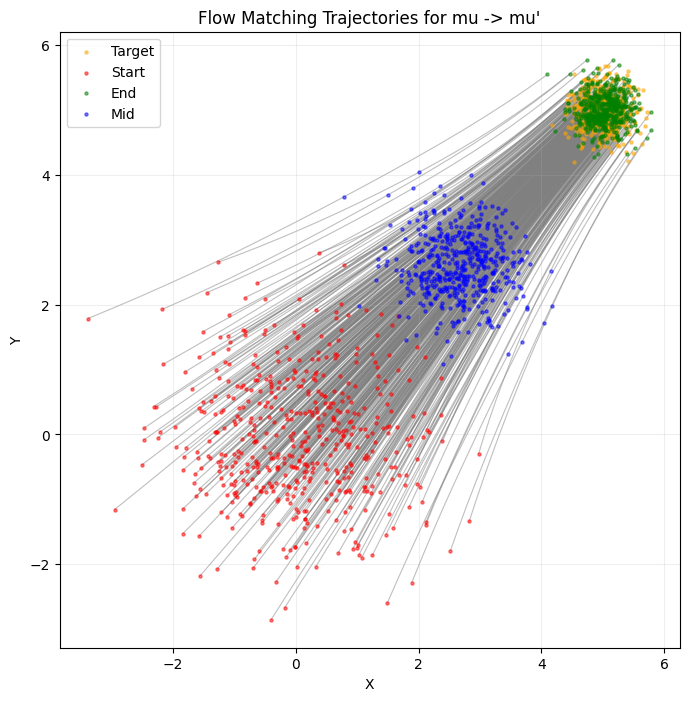

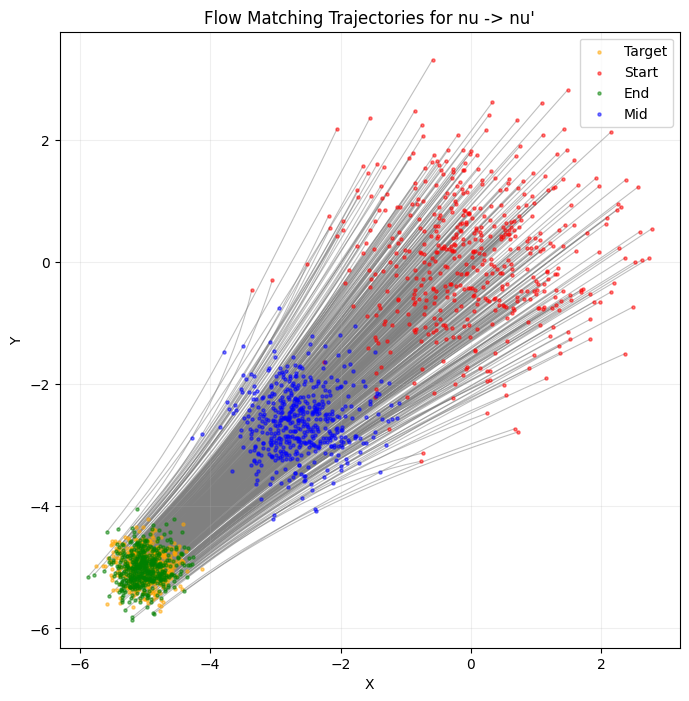

In [40]:
flow_mu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(device)
flow_nu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(device)

optimizer_mu = optim.Adam(flow_mu.parameters(), lr=1e-3)
optimizer_nu = optim.Adam(flow_nu.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

batch_size = 2048
epochs_marginal = 2500
sigma = 0.1

def interpolate(x0, x1, t, sigma):
    return (1 - t) * x0 + t * x1 + sigma * torch.randn_like(x0) * torch.sqrt(t * (1 - t))

pbar = trange(epochs_marginal, desc="Training Marginal Bridges")
for epoch in pbar:
    x0, y0 = coupling_dist.coupling_sample(batch_size)
    x1, y1 = new_source_dist.sample(batch_size), new_target_dist.sample(batch_size)
    x0, x1, y0, y1 = x0.to(device), x1.to(device), y0.to(device), y1.to(device)

    t = torch.rand(batch_size, 1).to(device)
    xt, yt = interpolate(x0, x1, t, sigma), interpolate(y0, y1, t, sigma)

    u_t, v_t = flow_mu(torch.cat([xt, t], dim=1)), flow_nu(torch.cat([yt, t], dim=1))
    target_u_t, target_v_t = x1 - x0, y1 - y0

    optimizer_mu.zero_grad()
    optimizer_nu.zero_grad()

    loss_mu = loss_fn(u_t, target_u_t)
    loss_mu.backward()
    optimizer_mu.step()

    loss_nu = loss_fn(v_t, target_v_t)
    loss_nu.backward()
    optimizer_nu.step()

    pbar.set_postfix({"Loss mu": loss_mu.item(), "Loss nu": loss_nu.item()})


cfm_mu = ConditionalFlowMatching(source_dist, new_source_dist, flow_mu, sigma=sigma)
cfm_nu = ConditionalFlowMatching(target_dist, new_target_dist, flow_nu, sigma=sigma)

n_samples = 500
n_timesteps = 20

time = torch.linspace(0, 1, n_timesteps)
traj_mu = cfm_mu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
traj_nu = cfm_nu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
target_mu_samples = new_source_dist.sample(n_samples).cpu().numpy()
target_nu_samples = new_target_dist.sample(n_samples).cpu().numpy()

plot_2d_flow_trajectories(trajectories=traj_mu, t=time, n_trajectories=n_samples, target_points=target_mu_samples, title=f"Flow Matching Trajectories for mu -> mu'")
plot_2d_flow_trajectories(trajectories=traj_nu, t=time, n_trajectories=n_samples, target_points=target_nu_samples, title=f"Flow Matching Trajectories for nu -> nu'")

## Testing coupling evolution

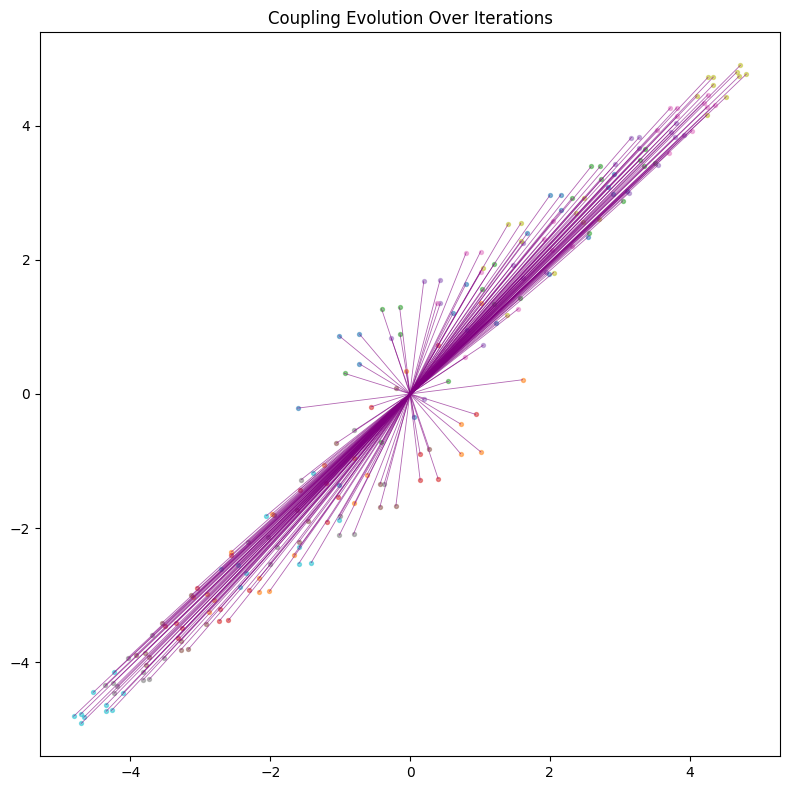

In [41]:
dataset_size = 10
current_coupling_dist = FixedSizeCouplingDistribution(coupling_dist, size=dataset_size)
current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu() # (2, dataset_size, dim)

n_iterations = 10
delta = 1.0 / n_iterations

trajectories = [current_coupling_dist.dataset.clone().cpu().numpy()]

for iteration in range(n_iterations):
    t_current = iteration / n_iterations
    x, y = current_coupling_dist.dataset[0].to(device), current_coupling_dist.dataset[1].to(device)

    t_tensor = torch.full((x.shape[0], 1), t_current).to(device)

    u_t = flow_mu(torch.cat([x, t_tensor], dim=1))
    v_t = flow_nu(torch.cat([y, t_tensor], dim=1))

    x_next = x.detach() + delta * u_t
    y_next = y.detach() + delta * v_t

    x_next = x_next.detach().cpu()
    y_next = y_next.detach().cpu()

    current_coupling_dist.dataset = torch.stack([x_next, y_next], dim=0)

    trajectories.append(current_coupling_dist.dataset.clone().cpu().numpy())

fig = plt.figure(figsize=(8, 8))
for i in range(len(trajectories)-1):
    source_samples = trajectories[i][0]
    target_samples = trajectories[i][1]
    plt.scatter(source_samples[:, 0], source_samples[:, 1], s=8, alpha=0.5, label=f'Source Samples t={i}')
    plt.scatter(target_samples[:, 0], target_samples[:, 1], s=8, alpha=0.5, label=f'Target Samples t={i}')
    plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=0.6, lw=0.6)
plt.title('Coupling Evolution Over Iterations')
plt.tight_layout()
plt.show()

In [42]:
import numpy as np

def plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model, device):
    """Visualizes the coupling, the learned weights, and the vector field."""
    x_ref_np = x_ref.detach().cpu().numpy()
    y_ref_np = y_ref.detach().cpu().numpy()
    with torch.no_grad():
        a = f_net(x_ref).view(-1)
        b = g_net(y_ref).view(-1)

        log_weights = a + b

    # Grid for vector field
    grid_n = 20
    x = np.linspace(-10, 10, grid_n)
    y = np.linspace(-10, 10, grid_n)
    X, Y = np.meshgrid(x, y)
    grid = torch.tensor(np.stack([X.flatten(), Y.flatten()], axis=1), dtype=torch.float32).to(device)

    # Flow Vector Field (at t=0 for this step)
    t_zeros = torch.zeros(grid.shape[0], 1).to(device)
    with torch.no_grad():
        vectors = flow_model(torch.cat([grid, grid, t_zeros], dim=1)).cpu().numpy()
        # vectors = flow_model(torch.cat([grid, torch.randn_like(grid), t_zeros], dim=1)).cpu().numpy()
    U = vectors[:, 0].reshape(grid_n, grid_n)
    V = vectors[:, 1].reshape(grid_n, grid_n)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sc = axes[0].scatter(x_ref_np[:, 0], x_ref_np[:, 1], c=log_weights.cpu().numpy(), cmap='viridis', s=5, alpha=0.6)
    axes[0].set_title(f"Step {step}: Source Samples\n(Color = Log Learned Weight)")
    plt.colorbar(sc, ax=axes[0])
    axes[0].set_xlim(-10, 10); axes[0].set_ylim(-10, 10)

    axes[1].scatter(y_ref_np[:, 0], y_ref_np[:, 1], c=log_weights.cpu().numpy(), s=5, alpha=0.3, label='Target Coupling Y')
    axes[1].set_title(f"Step {step}: Target Samples")
    axes[1].set_xlim(-10, 10); axes[1].set_ylim(-10, 10)

    axes[2].quiver(X, Y, U, V, color='blue', alpha=0.8)
    axes[2].set_title(f"Step {step}: Learned Flow Field (v_t)")
    axes[2].set_xlim(-10, 10); axes[2].set_ylim(-10, 10)

    plt.tight_layout()
    plt.show()

In [43]:
def print_mass_conservation_check(x, y, f_net, g_net, delta):
    """
    Checks if the learned potentials a(x) and b(y) naturally conserve mass.
    The goal is for the Net Mass Flux to be 0 (Mean Weight - 1 = 0).
    """
    with torch.no_grad():
        a = f_net(x)
        b = g_net(y)

        # 1. Compute the raw theoretical multiplier implied by the networks
        # We do NOT subtract max() here because we want to check the absolute scale
        raw_log_w = (a + b) * delta
        raw_w = torch.exp(raw_log_w)

        # 2. Compute the Mass Flux Error
        # If mass is conserved, the average multiplier should be exactly 1.0.
        # This value should be close to 0.0.
        mass_flux_error = raw_w.mean() - 1.0

    print(f"--- Mass Conservation Check ---")
    print(f"Mean Weight:       {raw_w.mean().item():.5f} (Target: 1.0)")
    print(f"Net Mass Flux:     {mass_flux_error.item():.5f} (Target: 0.0)")

### Learning initial flow matching between mu and nu

In [44]:
n_iterations = 100
epochs_dual_per_step = 100
epochs_cfm_per_step = 250

delta = 1.0 / n_iterations
dataset_size = 200_000
batch_size = 2048

current_coupling_dist = FixedSizeCouplingDistribution(coupling_dist, size=dataset_size)
current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu()

f_net = MLP(dim=2, out_dim=1, w=16, time_varying=False).to(device)
g_net = MLP(dim=2, out_dim=1, w=16, time_varying=False).to(device)

# flow_model = MLP(dim=2, out_dim=2, w=32, time_varying=True).to(device)
# flow_model = MLP(dim=4, out_dim=4, w=16, time_varying=True)
flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(device)
flow_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(device)
previous_flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
previous_flow_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
# flow_model = LagrangianFlowField(net=base_flow_model, dim=2).to(device)

optimizer_dual = optim.Adam(list(f_net.parameters()) + list(g_net.parameters()), lr=1e-4)
# cfm_optimizer = optim.Adam(flow_model.parameters(), lr=1e-3)
cfm_optimizer_mu = optim.Adam(flow_model_mu.parameters(), lr=5e-3)
cfm_optimizer_nu = optim.Adam(flow_model_nu.parameters(), lr=5e-3)

In [45]:
# flow_model.to(device)
flow_model_mu.to(device)
flow_model_nu.to(device)

pbar = trange(10000, desc="Overall Iterations")
for _ in pbar:
    x0, x1 = current_coupling_dist.coupling_sample(batch_size)
    x0, x1 = x0.to(device), x1.to(device)

    s = torch.rand(batch_size, 1).to(device)
    xs_mu = interpolate(x0, x1, s, sigma)
    xs_nu = interpolate(x1, x0, s, sigma)

    # u_s = flow_model(torch.cat([xs, x0, s], dim=1))
    u_s_mu = flow_model_mu(torch.cat([xs_mu, x0, s], dim=1))
    u_s_nu = flow_model_nu(torch.cat([xs_nu, x1, s], dim=1))
    # loss = ((u_s - torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1))**2).mean()
    target_mu = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)
    target_nu = torch.cat([x0 - x1, torch.zeros_like(x0)], dim=1)
    loss_mu = ((u_s_mu - target_mu)**2).mean()
    loss_nu = ((u_s_nu - target_nu)**2).mean()

    # cfm_optimizer.zero_grad()
    # loss.backward()
    # cfm_optimizer.step()
    # pbar.set_postfix({"CFM Loss": loss.item()})

    cfm_optimizer_mu.zero_grad()
    loss_mu.backward()
    cfm_optimizer_mu.step()
    cfm_optimizer_nu.zero_grad()
    loss_nu.backward()
    cfm_optimizer_nu.step()
    pbar.set_postfix({"CFM Loss mu": loss_mu.item(), "CFM Loss nu": loss_nu.item()})

Overall Iterations: 100%|██████████| 10000/10000 [01:02<00:00, 160.39it/s, CFM Loss mu=2.8e-5, CFM Loss nu=9.07e-5]  


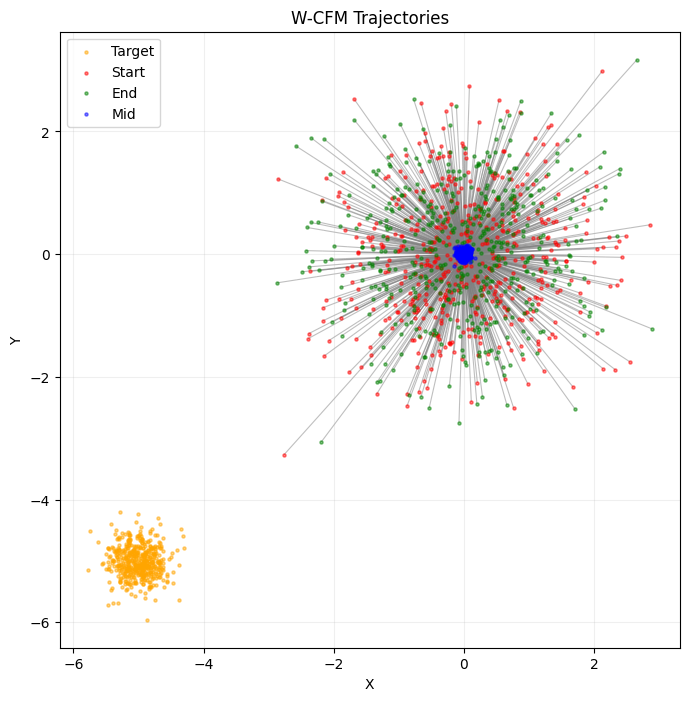

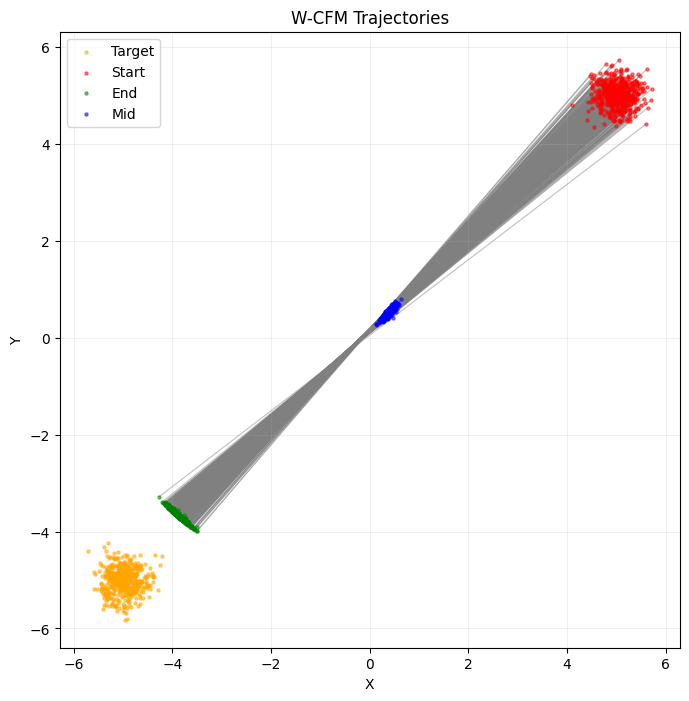

In [46]:
flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 500
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init, _ = current_coupling_dist.coupling_sample(n_samples)
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories")
    plt.show()

flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 500
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init, _ = new_source_dist.sample(n_samples), None
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories")
    plt.show()

In [47]:
import copy

initial_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
initial_model_mu.load_state_dict(flow_model_mu.state_dict())
initial_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
initial_model_nu.load_state_dict(flow_model_nu.state_dict())

<All keys matched successfully>

In [48]:
# # Print first layer of initial model
# first_layer_weights = initial_model.net[0].weight.data.cpu().numpy()
# print("First layer weights of the initial model:")
# print(first_layer_weights[:4])

## Learn weights

CFM Loss: 0.0002: 100%|██████████| 250/250 [00:01<00:00, 204.27it/s]


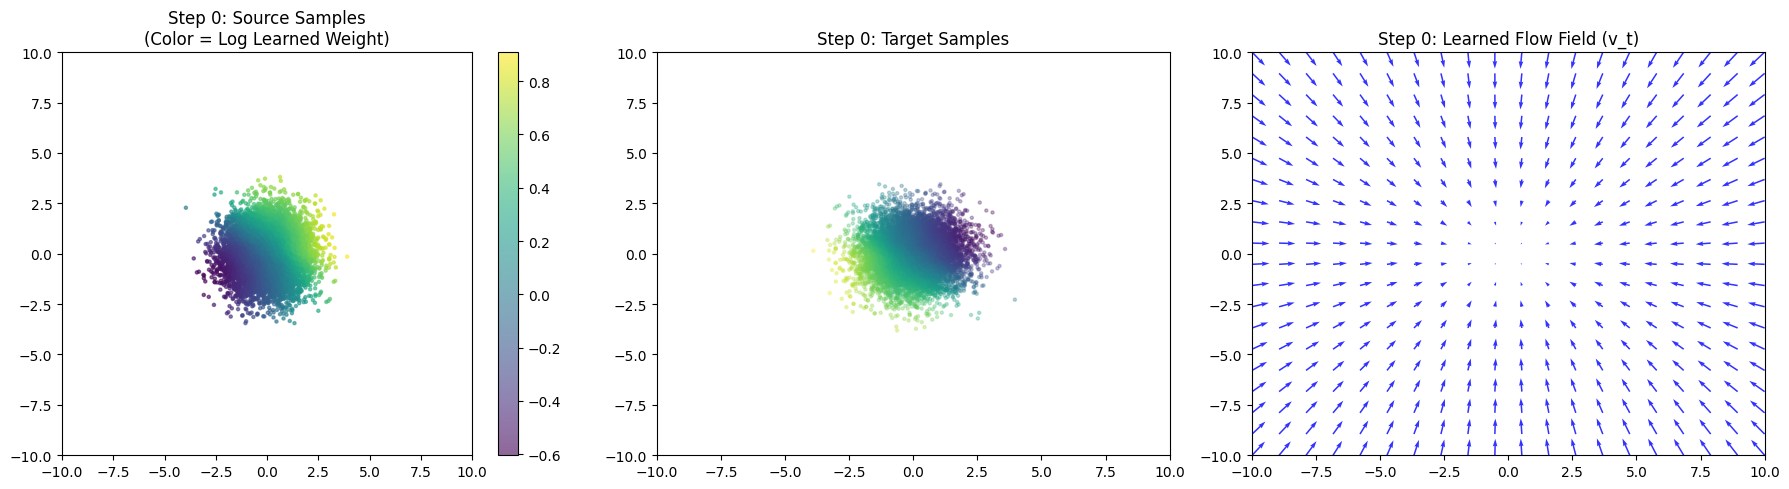

Step 0: MSE 0.0000 (min: 0.0000, max: 0.0000)


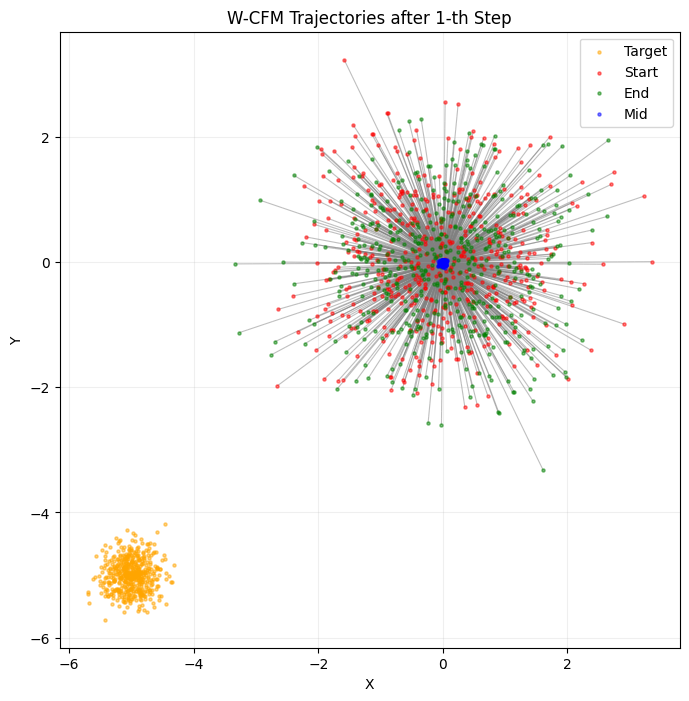

CFM Loss: 0.0000: 100%|██████████| 250/250 [00:01<00:00, 182.79it/s]


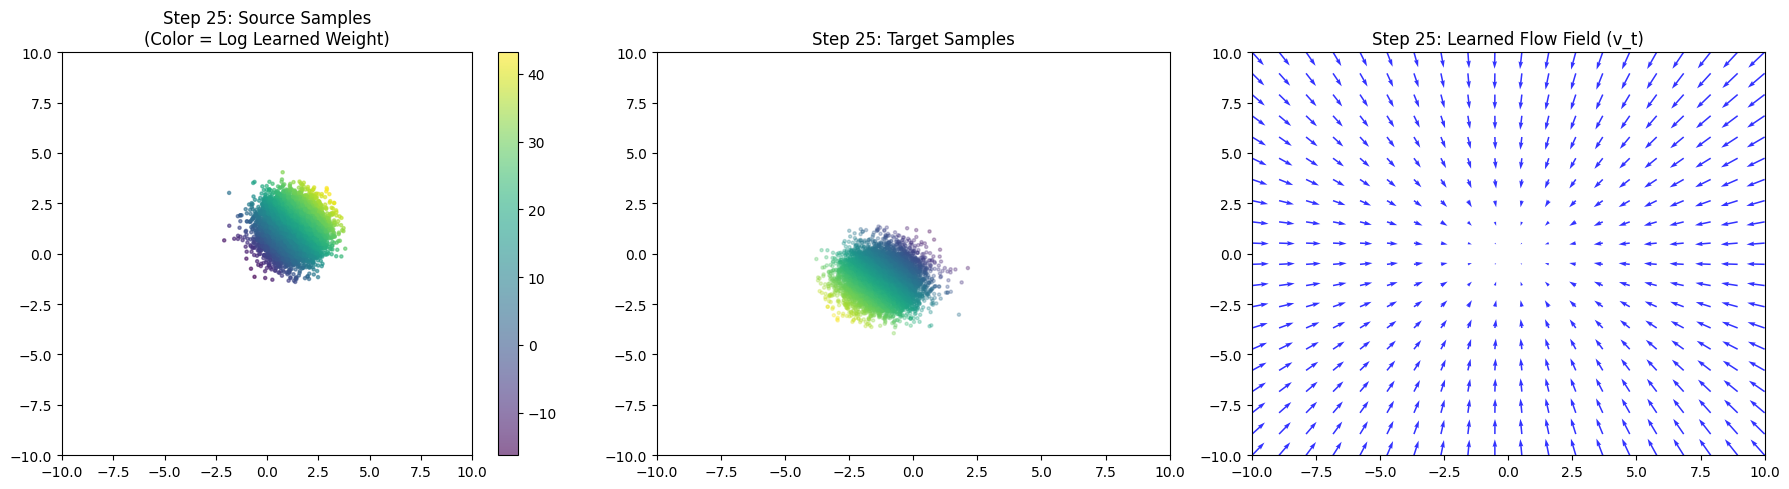

Step 25: MSE 0.0004 (min: 0.0000, max: 0.0161)


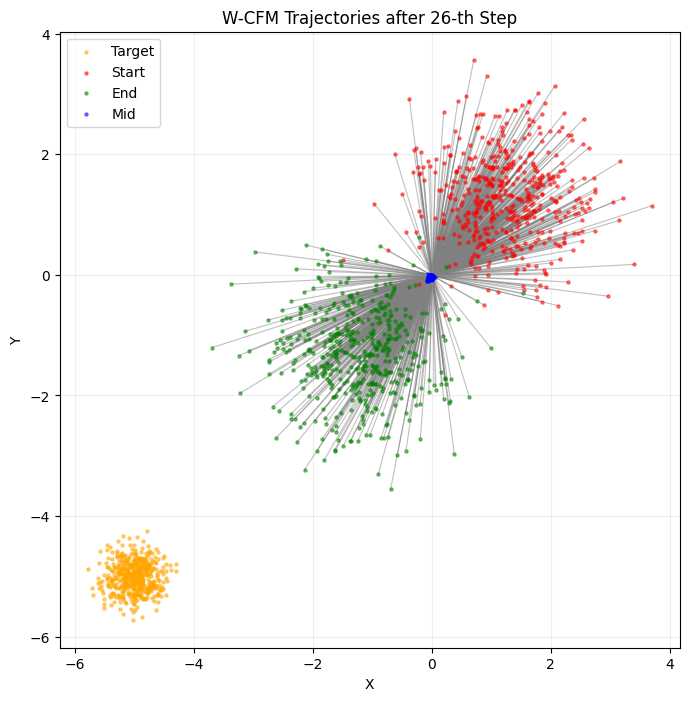

CFM Loss: 0.0001: 100%|██████████| 250/250 [00:01<00:00, 150.99it/s]


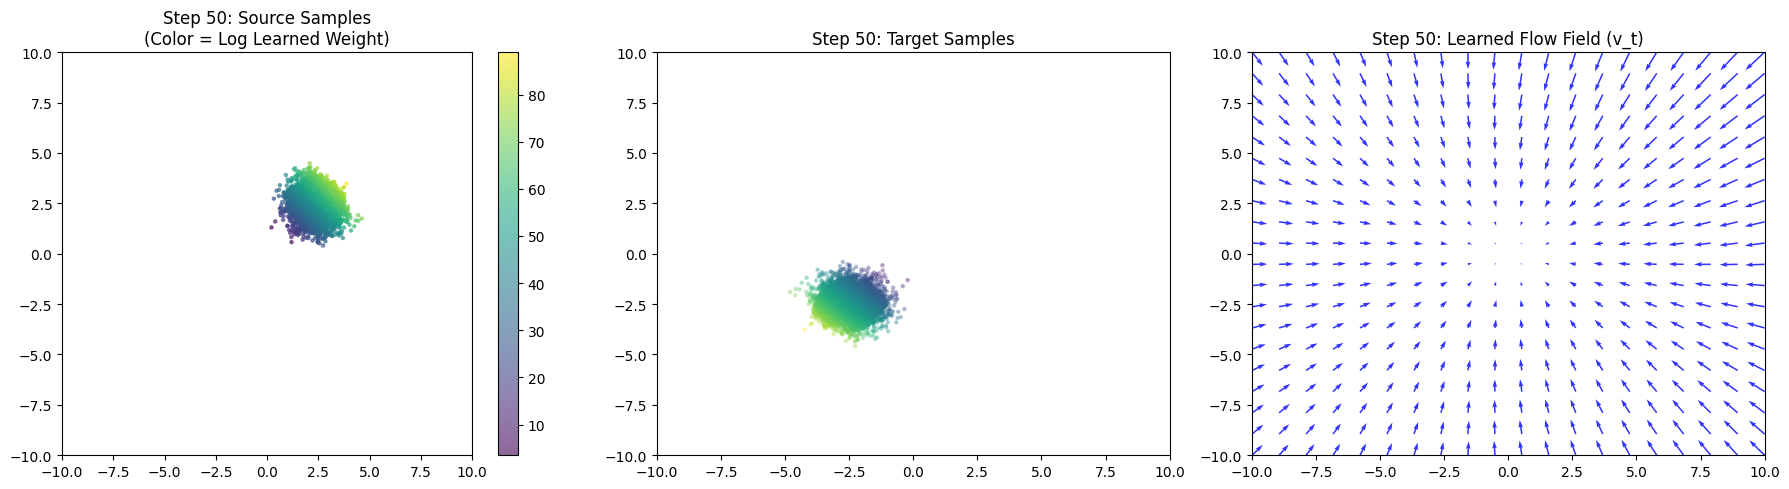

Step 50: MSE 0.0056 (min: 0.0000, max: 0.1366)


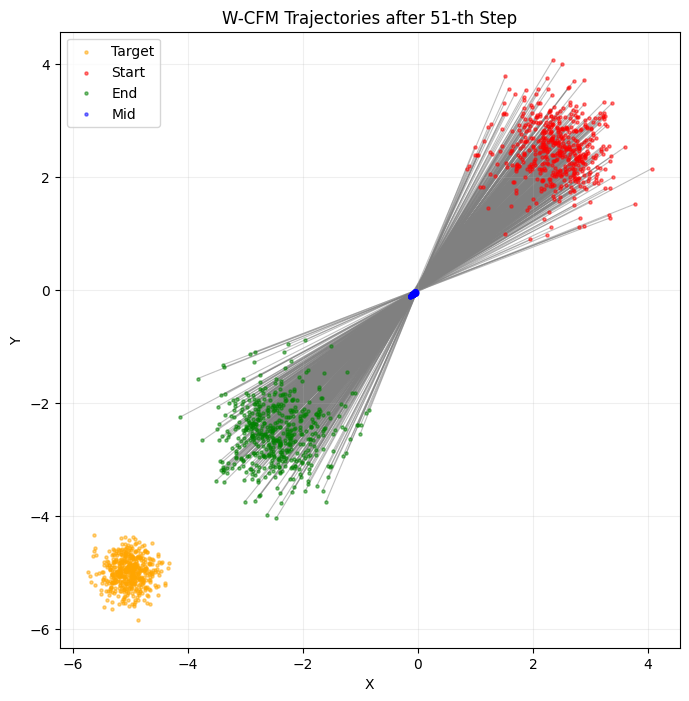

CFM Loss: 0.0001: 100%|██████████| 250/250 [00:01<00:00, 179.84it/s]


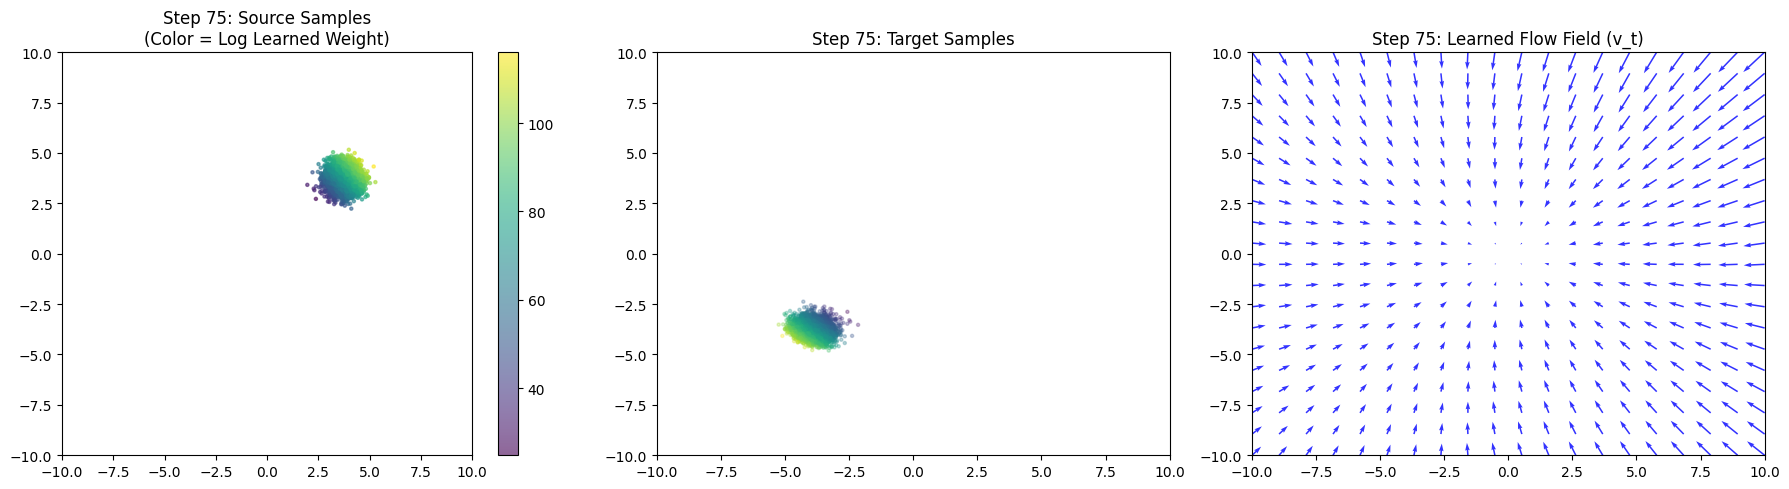

Step 75: MSE 0.0220 (min: 0.0000, max: 0.1393)


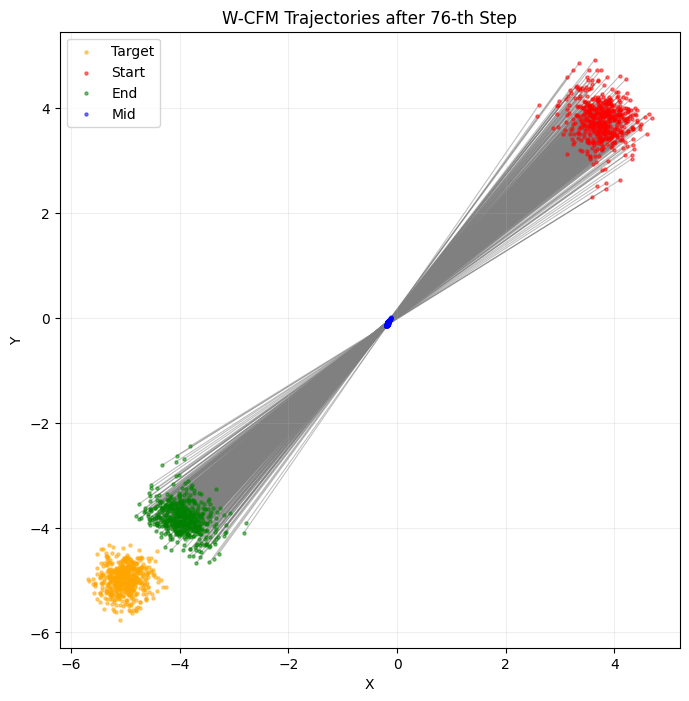

100%|██████████| 2/2 [00:00<00:00,  8.50it/s]


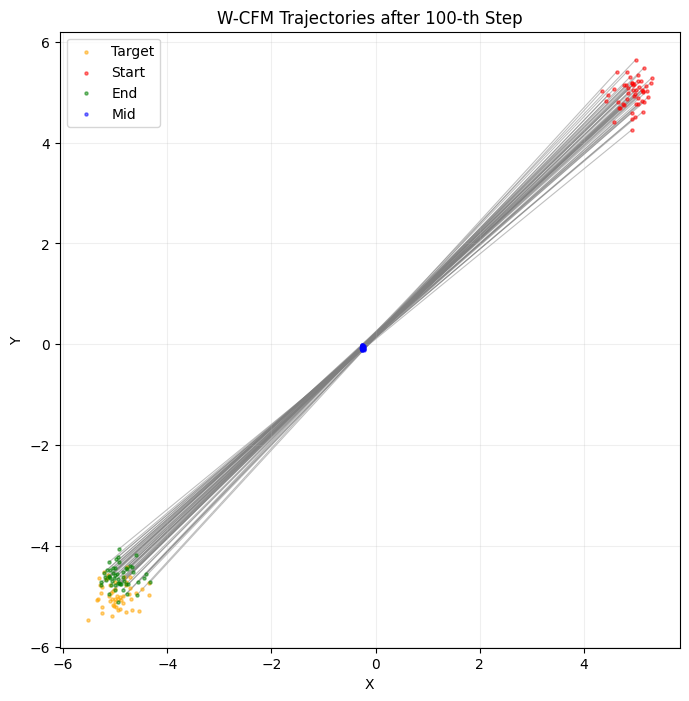

In [49]:
import copy
from dualwcfm.distributions.distribution import Distribution, FixedSizeDistribution

mode = "implicit"

tau = 0.05       # Polyak averaging rate (Soft update)
gp_lambda = 0.1  # Gradient penalty weight for f and g
max_weight = 10.0

batch_size = 4096*2

mu_dist, nu_dist = current_coupling_dist.get_marginals()
mu_dist = FixedSizeDistribution(mu_dist, size=dataset_size)
nu_dist = FixedSizeDistribution(nu_dist, size=dataset_size)

def soft_update(target_net, source_net, tau):
    for target_param, source_param in zip(target_net.parameters(), source_net.parameters()):
        target_param.data.copy_(target_param.data * (1.0 - tau) + source_param.data * tau)

# flow_model = copy.deepcopy(initial_model)
# flow_model.to(device)
# previous_flow_model = copy.deepcopy(flow_model)
# previous_flow_model.eval()
# previous_flow_model = MLP(dim=4, out_dim=4, w=16, time_varying=True)
# cfm_optimizer = optim.Adam(flow_model.parameters(), lr=5e-3)

mse_errors = {"mse": [], "min": [], "max": []}
# n_iterations = 500
for step in range(n_iterations):
    t_current = step * delta
    t = torch.full((batch_size, 1), t_current).to(device)

    # previous_flow_model.load_state_dict(flow_model.state_dict())
    # previous_flow_model.to(device)
    # previous_flow_model.eval()

    previous_flow_model_mu.load_state_dict(flow_model_mu.state_dict())
    previous_flow_model_nu.load_state_dict(flow_model_nu.state_dict())
    previous_flow_model_mu.to(device)
    previous_flow_model_nu.to(device)
    previous_flow_model_mu.eval()
    previous_flow_model_nu.eval()

    f_net.train()
    g_net.train()

    pbar = trange(epochs_dual_per_step)
    for _ in pbar:
        x, y = current_coupling_dist.coupling_sample(batch_size)
        x_mu, y_nu = mu_dist.sample(batch_size).to(device), nu_dist.sample(batch_size).to(device)

        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            u_t = flow_mu(torch.cat([x_mu, t], dim=1))
            v_t = flow_nu(torch.cat([y_nu, t], dim=1))

        x.requires_grad_(True)
        y.requires_grad_(True)
        x_mu.requires_grad_(True)
        y_nu.requires_grad_(True)

        a = f_net(x)#torch.cat([x, t], dim=1))
        b = g_net(y)#torch.cat([y, t], dim=1))
        a_mu = f_net(x_mu)
        b_nu = g_net(y_nu)

        # Loss computation (Variational)
        term_coupling = torch.mean((a - a.mean() + b - b.mean())**2)

        # Divergence terms
        grad_a = torch.autograd.grad(a_mu.sum(), x_mu, create_graph=True, retain_graph=True, only_inputs=True)[0]
        grad_b = torch.autograd.grad(b_nu.sum(), y_nu, create_graph=True, retain_graph=True, only_inputs=True)[0]

        term_flow_a = torch.mean(torch.sum(grad_a * u_t, dim=1))
        term_flow_b = torch.mean(torch.sum(grad_b * v_t, dim=1))

        # L2 Regularization
        term_reg = 1e-3 * (torch.mean(a**2) + torch.mean(b**2)) + 1e-3 * (torch.mean(a_mu**2) + torch.mean(b_nu**2))

        # Lipschitz Constraint
        gp_f = ((grad_a.norm(2, dim=1) - 1) ** 2).mean()
        gp_g = ((grad_b.norm(2, dim=1) - 1) ** 2).mean()

        loss = 0.5 * term_coupling - term_flow_a - term_flow_b + term_reg + gp_lambda * (gp_f + gp_g)

        optimizer_dual.zero_grad()
        loss.backward()
        optimizer_dual.step()

        pbar.set_description(f"Dual Loss: {loss.item():.4f}")

    # Plot a heatmap of a_t(x) + b_t(y) on the current coupling
    # if step > 0 and step % 5 == 0:
    #     x, y = mu_dist.sample(1000).to(device), nu_dist.sample(1000).to(device)
    #     true_a = -1/t_current + 2/t_current**2 * (x - 5*t_current)**2 + 20/t_current * (x[:, 0] + x[:, 1] - 10*t_current)
    #     true_b = -1/t_current + 2/t_current**2 * (y + 5*(1 - t_current))**2 - 20/t_current * (y[:, 0] + y[:, 1] + 10*t_current)

    #     with torch.no_grad():
    #         a = f_net(x).view(-1)
    #         b = g_net(y).view(-1)

    #         log_weights = (a + b) * delta
    #         true_log_weights = (true_a + true_b) * delta

    #         mse = nn.functional.mse_loss(log_weights, true_log_weights).item()
    #         print(f"Step {step}: MSE between learned and true log-weights: {mse:.6f}")

    # 3. Learn weighted-CFM at next step
    # flow_model.train()
    flow_model_mu.train()
    flow_model_nu.train()
    f_net.eval()
    g_net.eval()

    # cfm_scheduler = optim.lr_scheduler.CosineAnnealingLR(cfm_optimizer, T_max=epochs_cfm_per_step)

    pbar = trange(epochs_cfm_per_step)
    for epoch in pbar:
        x0, x1 = current_coupling_dist.coupling_sample(batch_size)
        x0, x1 = x0.to(device), x1.to(device)

        s = torch.rand(batch_size, 1).to(device)

        # u_s = flow_model(torch.cat([xs, x0, s], dim=1))
        if step % 2 == 0:
            xs = interpolate(x0, x1, s, sigma)
            u_s_full = flow_model_mu(torch.cat([xs, x0, s], dim=1))
            u_s = u_s_full[:, :2]
        else:
            xs = interpolate(x1, x0, s, sigma)
            u_s_full = flow_model_nu(torch.cat([xs, x1, s], dim=1))
            u_s = u_s_full[:, :2]

        with torch.no_grad():
            a, b = f_net(x0), g_net(x1)#torch.cat([x0, t], dim=1)), g_net(torch.cat([x1, t], dim=1)) # Not the same t
            r = a + b
            log_w = r * delta
            # log_w = log_w - torch.median(log_w)
            # weight = torch.exp(torch.clamp(log_w, max=5.0))
            weight = torch.exp(log_w)
            # log_w = log_w - log_w.max()
            # weight = torch.exp(log_w)
            # weight = weight / (weight.mean() + 1e-8)
            # weight = torch.clamp(weight, max=50.0)

            # stop_grad_u_s = flow_model(torch.cat([xs, x0, s], dim=1)).detach()
        if mode == "weight":
            schrodinger_u_s = (x1 - x0) if step % 2 == 0 else (x0 - x1)
            #+ (1 - 2*s) / (2 * t *(1 - t) + 1e-8) * (x - (t  * x1 + (1 - t) * x0))
            target_u_s = torch.cat([schrodinger_u_s, torch.zeros_like(x0)], dim=1)
            loss = (weight * (u_s_full - target_u_s)**2).mean()
        elif mode == "implicit":
            # raise NotImplementedError("Implicit mode not implemented yet.")
            with torch.no_grad():
                b_hat_detached = u_s.detach()
                if step % 2 == 0:
                    b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1))[:, :2]
                    target = x1 - x0
                else:
                    b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1))[:, :2]
                    target = x0 - x1

                # ITM Residual: T_ITM = b_ta + (exp(hr) - 1) * (dot_I - b_hat)
                itm_target = b_ta + (weight - 1.0) * (target - b_hat_detached)
                full_target = torch.cat([itm_target, torch.zeros_like(x0)], dim=1)

            # loss = nn.functional.mse_loss(u_s, itm_target)
            loss = nn.functional.mse_loss(u_s_full, full_target)
        elif mode == "explicit":
            with torch.no_grad():
                prev_val = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1)).detach()[:, :2]
                residual = (x1 - x0) * r - prev_val * r
                schrodinger_target = prev_val + delta * residual
            schrodinger_target = torch.cat([schrodinger_target, torch.zeros_like(x0)], dim=1)
            loss = ((u_s - schrodinger_target)**2).mean()
        # Derivative of (1-t)x0 + t x1 + sigma*sqrt(t(1-t))eps
        # flow_true = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)
        # target_u_s = flow_true + (weight - 1.0) * (flow_true - stop_grad_u_s)

        # loss = torch.mean(weight * (u_s - target_u_s)**2)
        # loss = torch.mean(weight * torch.sum((u_s - target_u_s)**2, dim=1, keepdim=True))

        # cfm_optimizer.zero_grad()
        # loss.backward()
        # cfm_optimizer.step()
        cfm_optimizer_mu.zero_grad()
        cfm_optimizer_nu.zero_grad()
        loss.backward()
        cfm_optimizer_mu.step()
        cfm_optimizer_nu.step()
        # cfm_scheduler.step()

        # if mode == "implicit":
        #     soft_update(previous_flow_model, flow_model, tau)

        pbar.set_description(f"CFM Loss: {loss.item():.4f}")

    if step % 25 == 0:
        x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
        x_ref, y_ref = x_ref.to(device), y_ref.to(device)
        plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model_mu, device)

        # Print actual error between current coupling and optimal coupling that uses anticorrelate function
        with torch.no_grad():
            loss = (y_ref + x_ref)**2
            error = torch.mean(loss).item()
            print(f"Step {step}: MSE {error:.4f} (min: {loss.min().item():.4f}, max: {loss.max().item():.4f})")
        mse_errors["mse"].append(error)
        mse_errors["min"].append(loss.min().item())
        mse_errors["max"].append(loss.max().item())

        # first_layer_weights = flow_model.net[0].weight.data.cpu().numpy()
        # print("First layer weights of the initial model:")
        # print(first_layer_weights[:4])

        # 4. Visualize learned W-CFM at current step
        flow_model_mu.eval()
        with torch.no_grad():
            cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
            n_samples = 500
            n_timesteps = 50
            time = torch.linspace(0, 1, n_timesteps)
            # x_init = new_source_dist.sample(n_samples).to(device)
            # x_init = source_dist.sample(n_samples).to(device)
            x_init, _ = current_coupling_dist.coupling_sample(n_samples)
            x_init = x_init.to(device)
            x_init_extended = torch.cat([x_init, x_init], dim=1)
            traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
            target_samples = new_target_dist.sample(n_samples).cpu().numpy()

            plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
            plt.show()

    chunks = 100_000
    num_steps = 50
    dt = 1.0 / num_steps
    flow_mu.eval()
    flow_nu.eval()
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    with torch.no_grad():
        for i in trange(0, dataset_size, chunks):
            samples = current_coupling_dist.dataset[:, i:i+chunks]
            # x, y = samples[0].to(device), samples[1].to(device)
            x_mu, y_nu = mu_dist.dataset[i:i+chunks].to(device), nu_dist.dataset[i:i+chunks].to(device)

            t_tensor = torch.full((x_mu.shape[0], 1), t_current).to(device)

            x_mu_next = x_mu.detach() + delta * flow_mu(torch.cat([x_mu, t_tensor], dim=1))
            y_nu_next = y_nu.detach() + delta * flow_nu(torch.cat([y_nu, t_tensor], dim=1))

            if step % 2 == 0:
                # x_next = x.detach() + delta * flow_mu(torch.cat([x, t_tensor], dim=1))
                x_next = x_mu_next.detach().clone()

                xt = x_next.clone()
                for j in range(num_steps):
                    t = torch.ones(x_next.shape[0], 1).to(device) * (j * dt)
                    vt = flow_model_mu(torch.cat([xt, x_next, t], dim=1))[:, :2]
                    xt = xt + vt * dt
                y_next = xt.clone()
            else:
                # y_next = y.detach() + delta * flow_nu(torch.cat([y, t_tensor], dim=1))
                y_next = y_nu_next.detach().clone()

                yt = y_next.clone()
                for j in range(num_steps):
                    t = torch.ones(y_next.shape[0], 1).to(device) * (j * dt)
                    vt = flow_model_nu(torch.cat([yt, y_next, t], dim=1))[:, :2]
                    yt = yt + vt * dt
                x_next = yt.clone()


            # 2. Advance y (Target Marginal) by delta
            # Evaluate flow_model at t=1 (the target end)

            # We use the coupled velocity b_t,a+h(y, x_next, 1)
            # to move y into the next tilted marginal
            # k1_v = flow_model(torch.cat([y, x_next, s_one], dim=1))[:, :2]
            # mid_y = y + 0.5 * delta * k1_v
            # y_next = y + delta * flow_model(torch.cat([mid_y, x_next, s_one], dim=1))[:, :2]
            # t_one = torch.ones(x.shape[0], 1).to(device)
            # y_next = y.detach() + delta * flow_model(torch.cat([y, x_next, t_one], dim=1))[:, :2]

            # x_next = x.detach() + delta * flow_mu(torch.cat([x, t_tensor], dim=1))
            # xt = x_next.clone()
            # for step_idx in range(num_steps):
            #     s = torch.full((x.shape[0], 1), step_idx / num_steps).to(device)
            #     # We use the updated x as the conditioning 'x0' to maintain 
            #     # the Schrödinger Bridge coupling for the next tilt step.
            #     k1 = flow_model(torch.cat([xt, x, s], dim=1))[:, :2]
            #     mid_xt = xt + 0.5 * dt * k1
            #     k2 = flow_model(torch.cat([mid_xt, x, s + (0.5 * dt / delta)], dim=1))[:, :2]
            #     xt = xt + dt * k2

            # y_next = xt
            # u_t = flow_mu(torch.cat([x, t_tensor], dim=1))

            # x_next = x.detach() + delta * u_t

            # x_init = torch.cat([x_next, x_next], dim=1)
            # traj = cfm.get_trajectory(x0=x_init, n_timesteps=num_steps)
            # y_next = traj[-1, :, :2]

            # Detach to free graph for next step
            x_next = x_next.detach().cpu()
            y_next = y_next.detach().cpu()

            current_coupling_dist.dataset[:, i:i+chunks] = torch.stack([x_next, y_next], dim=0)
            mu_dist.dataset[i:i+chunks] = x_mu_next
            nu_dist.dataset[i:i+chunks] = y_nu_next

flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 50
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init = new_source_dist.sample(n_samples).to(device)
    # x_init = new_source_dist.sample(n_samples).to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    # traj = cfm.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
    plt.show()

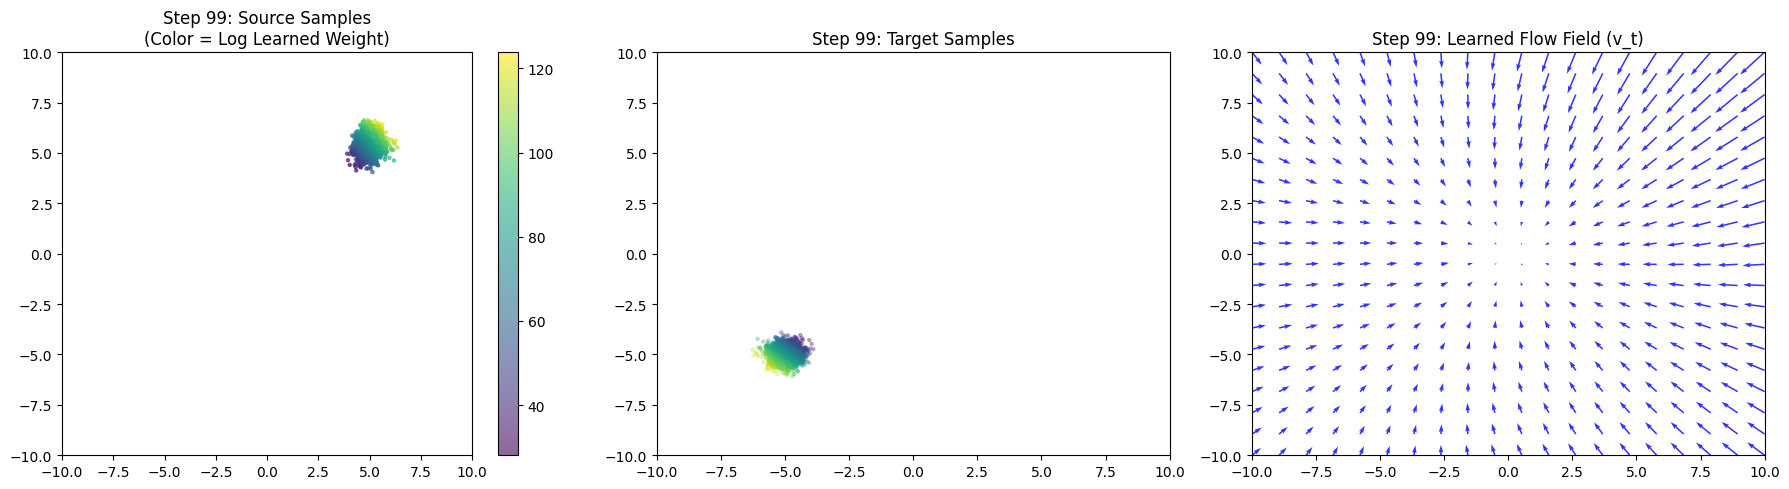

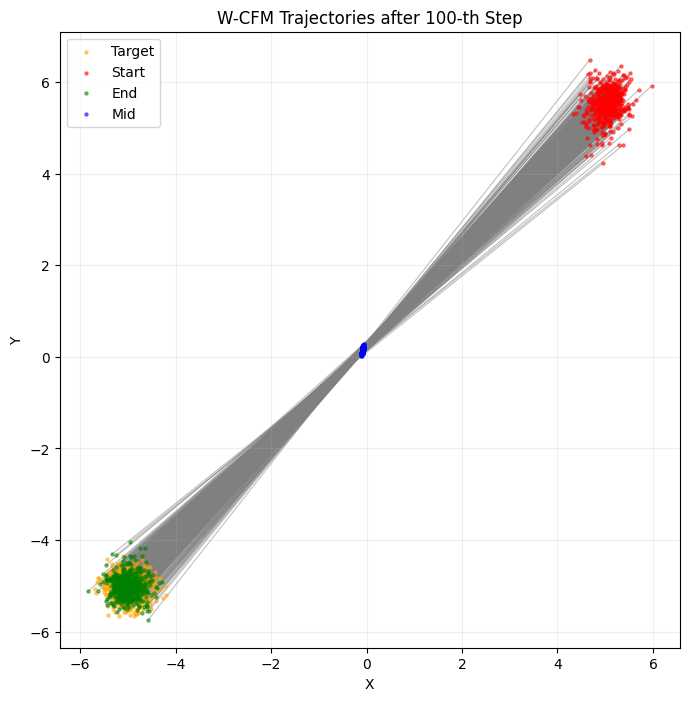

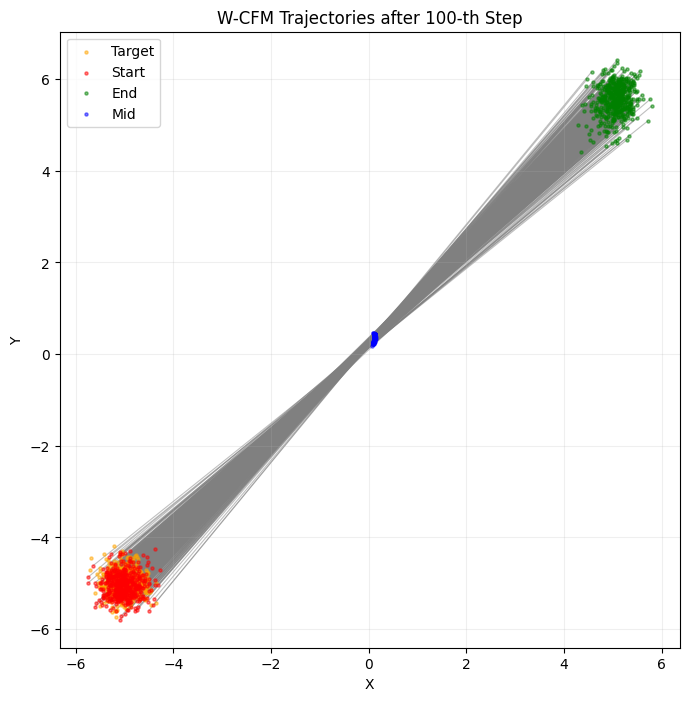

In [50]:
x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
x_ref, y_ref = x_ref.to(device), y_ref.to(device)
plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model_mu, device)

# 4. Visualize learned W-CFM at current step
flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 500
    n_timesteps = 50
    time = torch.linspace(0, 1, n_timesteps)
    # x_init = new_source_dist.sample(n_samples).to(device)
    # x_init = source_dist.sample(n_samples).to(device)
    x_init, _ = current_coupling_dist.coupling_sample(n_samples)
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
    plt.show()

flow_model_nu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_nu, sigma=0)
    n_samples = 500
    n_timesteps = 50
    time = torch.linspace(0, 1, n_timesteps)
    # x_init = new_source_dist.sample(n_samples).to(device)
    # x_init = source_dist.sample(n_samples).to(device)
    _, x_init = current_coupling_dist.coupling_sample(n_samples)
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
    plt.show()

# 4. Visualize learned W-CFM at current step
# flow_model_mu.eval()
# with torch.no_grad():
#     cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, initial_model, sigma=0)
#     n_samples = 500
#     n_timesteps = 50
#     time = torch.linspace(0, 1, n_timesteps)
#     # x_init = new_source_dist.sample(n_samples).to(device)
#     # x_init = source_dist.sample(n_samples).to(device)
#     x_init, _ = current_coupling_dist.coupling_sample(n_samples)
#     x_init = x_init.to(device)
#     x_init_extended = torch.cat([x_init, x_init], dim=1)
#     traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
#     target_samples = new_target_dist.sample(n_samples).cpu().numpy()

#     plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
#     plt.show()